# Credit Scoring - Exploratory Data Analysis

**Dataset:** Home Credit Default Risk
**Goal:** understand the data before building a probability-of-default model.

Each row of `application_train.csv` is one loan application.
The label `TARGET` = 1 means the client had payment difficulties (default), 0 means the loan was repaid.

This notebook covers:
1. Dataset overview and target imbalance
2. Missing values
3. Key numeric features vs the target (EXT_SOURCE, age, income)
4. Categorical features vs the target
5. Anomalies and data cleaning decisions
6. Auxiliary tables (bureau, previous_application) and why we aggregate them

Every finding ends with a decision: what we do about it in the preprocessing pipeline.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 130)
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

app_train = pd.read_csv("../../data/application_train.csv")
app_test = pd.read_csv("../../data/application_test.csv")

print("Train shape:", app_train.shape)
print("Test shape: ", app_test.shape)

Train shape: (307511, 122)
Test shape:  (48744, 121)


## 1. Target imbalance

How many clients actually default? This determines which metric is meaningful.

TARGET
0    282686
1     24825
Name: count, dtype: int64

Default rate: 8.07%


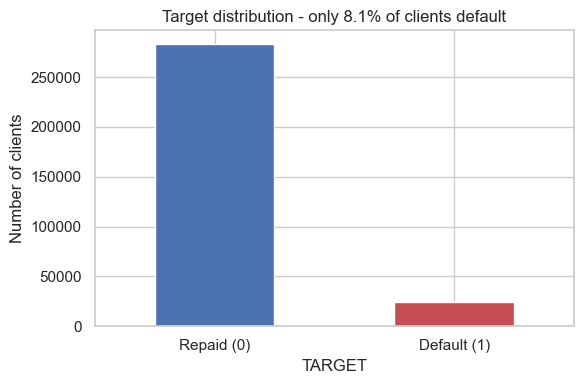

In [2]:
target_counts = app_train["TARGET"].value_counts()
target_rate = app_train["TARGET"].mean()

print(target_counts)
print(f"\nDefault rate: {target_rate:.2%}")

fig, ax = plt.subplots(figsize=(6, 4))
target_counts.plot(kind="bar", color=["#4c72b0", "#c44e52"], ax=ax)
ax.set_xticklabels(["Repaid (0)", "Default (1)"], rotation=0)
ax.set_ylabel("Number of clients")
ax.set_title(f"Target distribution - only {target_rate:.1%} of clients default")
plt.tight_layout()
plt.show()

### Finding: severe class imbalance (~8% defaults)

**Why accuracy is the wrong metric here:** a model that blindly predicts
"nobody defaults" would be right 92% of the time - 92% accuracy while being
completely useless to the bank, since it catches zero defaulters.

**Decision:** we evaluate with **AUC (Area Under the ROC Curve)** instead.
AUC measures how well the model *ranks* clients by risk: it is the probability
that a randomly chosen defaulter receives a higher risk score than a randomly
chosen good payer. It does not depend on a decision threshold and is not
inflated by the majority class. AUC = 0.5 is random guessing; the project
requires ≥ 0.55, ideally ≥ 0.62.

**Decision:** during model training we will also tell LightGBM about the
imbalance (`is_unbalance` / class weights) so the minority class is not ignored.

## 2. Missing values

Many columns are sparsely filled. We need to know how bad it is before choosing
how to handle it.

Columns with at least one missing value: 67 / 122

Top 20 columns by missing percentage:
COMMONAREA_MEDI             69.9
COMMONAREA_AVG              69.9
COMMONAREA_MODE             69.9
NONLIVINGAPARTMENTS_MODE    69.4
NONLIVINGAPARTMENTS_AVG     69.4
NONLIVINGAPARTMENTS_MEDI    69.4
FONDKAPREMONT_MODE          68.4
LIVINGAPARTMENTS_MODE       68.4
LIVINGAPARTMENTS_AVG        68.4
LIVINGAPARTMENTS_MEDI       68.4
FLOORSMIN_AVG               67.8
FLOORSMIN_MODE              67.8
FLOORSMIN_MEDI              67.8
YEARS_BUILD_MEDI            66.5
YEARS_BUILD_MODE            66.5
YEARS_BUILD_AVG             66.5
OWN_CAR_AGE                 66.0
LANDAREA_MEDI               59.4
LANDAREA_MODE               59.4
LANDAREA_AVG                59.4
dtype: float64


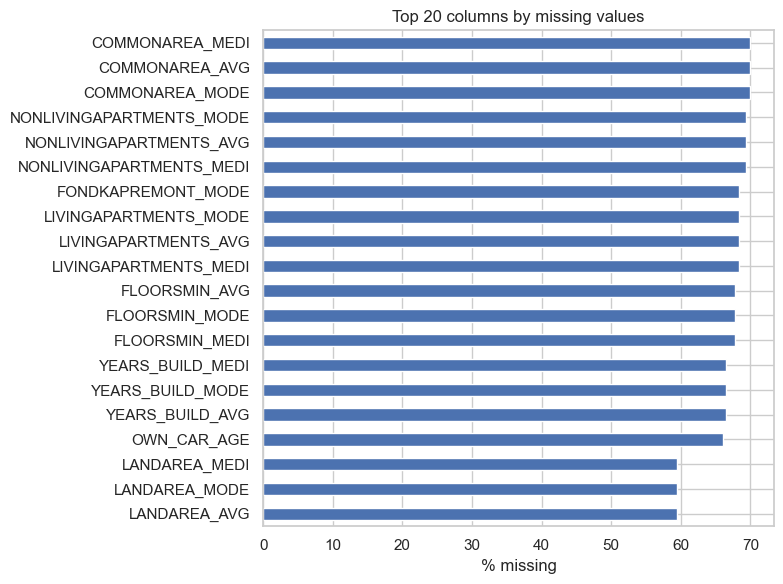

In [3]:
missing = app_train.isna().mean().sort_values(ascending=False)
missing_pct = (missing * 100).round(1)

print(f"Columns with at least one missing value: {(missing > 0).sum()} / {app_train.shape[1]}")
print("\nTop 20 columns by missing percentage:")
print(missing_pct.head(20))

fig, ax = plt.subplots(figsize=(8, 6))
missing_pct.head(20).plot(kind="barh", color="#4c72b0", ax=ax)
ax.invert_yaxis()
ax.set_xlabel("% missing")
ax.set_title("Top 20 columns by missing values")
plt.tight_layout()
plt.show()

### Finding: 67 of 122 columns contain missing values, some up to ~69%

Missingness here is often *informative* - e.g. a missing car age simply means
the client has no car, and missing building statistics mean Home Credit had no
data about the client's housing. Deleting these rows or columns would throw
away signal.

**Decision:** we will use **LightGBM**, which handles missing values natively -
at each tree split it learns which direction (left/right) missing values should
go, effectively treating "missing" as its own informative category. No manual
imputation is required for the model, which also avoids any risk of imputation
leakage between train and test.

(For the *client description visualizations* later we will still show raw values,
with missing ones explicitly labeled as "not provided".)

## 3. Which features separate defaulters from good payers?

The fastest way to scan 100+ numeric columns: correlation with the target.
Correlation is a crude tool (it only sees linear relationships) but it is a
good first radar.

In [4]:
correlations = app_train.corr(numeric_only=True)["TARGET"].sort_values()

print("Most NEGATIVE correlations (higher value -> less default):")
print(correlations.head(10))
print("\nMost POSITIVE correlations (higher value -> more default):")
print(correlations.tail(11))  # tail includes TARGET itself (corr = 1.0)

Most NEGATIVE correlations (higher value -> less default):
EXT_SOURCE_3                 -0.178919
EXT_SOURCE_2                 -0.160472
EXT_SOURCE_1                 -0.155317
DAYS_EMPLOYED                -0.044932
FLOORSMAX_AVG                -0.044003
FLOORSMAX_MEDI               -0.043768
FLOORSMAX_MODE               -0.043226
AMT_GOODS_PRICE              -0.039645
REGION_POPULATION_RELATIVE   -0.037227
ELEVATORS_AVG                -0.034199
Name: TARGET, dtype: float64

Most POSITIVE correlations (higher value -> more default):
DAYS_REGISTRATION              0.041975
FLAG_DOCUMENT_3                0.044346
REG_CITY_NOT_LIVE_CITY         0.044395
FLAG_EMP_PHONE                 0.045982
REG_CITY_NOT_WORK_CITY         0.050994
DAYS_ID_PUBLISH                0.051457
DAYS_LAST_PHONE_CHANGE         0.055218
REGION_RATING_CLIENT           0.058899
REGION_RATING_CLIENT_W_CITY    0.060893
DAYS_BIRTH                     0.078239
TARGET                         1.000000
Name: TARGET, dtype: f

### The EXT_SOURCE columns - our strongest predictors

`EXT_SOURCE_1/2/3` are normalized credit scores from external data providers -
essentially other agencies' opinions of the client. Unsurprisingly, they are
the most predictive columns in the whole table. Higher external score → lower
default probability.

Note on `DAYS_BIRTH`: it is *positive* only because ages are stored as
**negative day counts** (days before the application). Interpreted properly,
**older clients default less**.

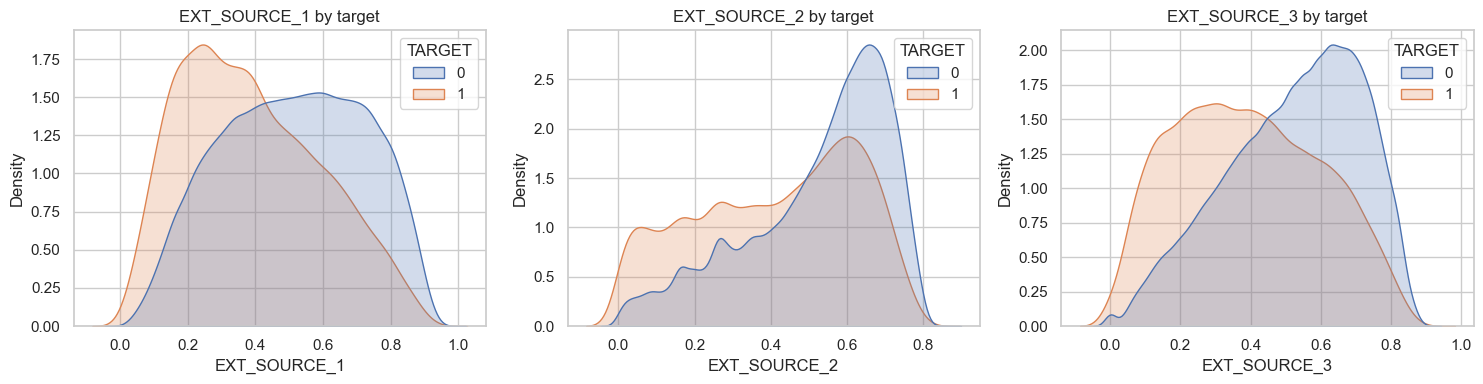

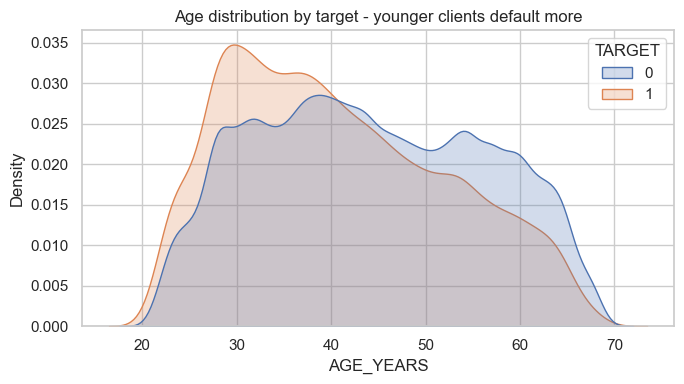

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]):
    sns.kdeplot(data=app_train, x=col, hue="TARGET",
                common_norm=False, fill=True, ax=ax)
    ax.set_title(f"{col} by target")
plt.tight_layout()
plt.show()

# Age in years, same idea
app_train["AGE_YEARS"] = -app_train["DAYS_BIRTH"] / 365.25

fig, ax = plt.subplots(figsize=(7, 4))
sns.kdeplot(data=app_train, x="AGE_YEARS", hue="TARGET",
            common_norm=False, fill=True, ax=ax)
ax.set_title("Age distribution by target - younger clients default more")
plt.tight_layout()
plt.show()

### Finding

- The EXT_SOURCE distributions of defaulters are visibly shifted left -
  these will be core model features, and we will also build combinations
  of them (mean, product) in feature engineering.
- Younger clients default more; age (converted to years) is a solid feature.

## 4. Anomaly: DAYS_EMPLOYED

`DAYS_EMPLOYED` should be a negative number (days employed before applying).
Let's check.

In [6]:
print(app_train["DAYS_EMPLOYED"].describe())

anomaly_value = app_train["DAYS_EMPLOYED"].max()
n_anomalous = (app_train["DAYS_EMPLOYED"] == anomaly_value).sum()
print(f"\nMax value: {anomaly_value} days  =  {anomaly_value/365.25:.0f} YEARS in the future")
print(f"Rows with this exact value: {n_anomalous} ({n_anomalous/len(app_train):.1%})")

anom = app_train["DAYS_EMPLOYED"] == anomaly_value
print(f"\nDefault rate - anomalous rows:  {app_train.loc[anom, 'TARGET'].mean():.2%}")
print(f"Default rate - normal rows:     {app_train.loc[~anom, 'TARGET'].mean():.2%}")

count    307511.000000
mean      63815.045904
std      141275.766519
min      -17912.000000
25%       -2760.000000
50%       -1213.000000
75%        -289.000000
max      365243.000000
Name: DAYS_EMPLOYED, dtype: float64

Max value: 365243 days  =  1000 YEARS in the future
Rows with this exact value: 55374 (18.0%)

Default rate - anomalous rows:  5.40%
Default rate - normal rows:     8.66%


### Finding: 365243 is a sentinel value ("no current employment"), not real data

~18% of clients carry this placeholder, and they default *less* than average
(mostly pensioners). The information is useful, the numeric value is garbage.

**Decision (for preprocess.py):**
1. Replace `DAYS_EMPLOYED == 365243` with NaN (LightGBM handles NaN natively).
2. Add a boolean flag column `DAYS_EMPLOYED_ANOMALY` so the model keeps the
   "not employed" signal explicitly.

This must be applied identically to train and test - it is a fixed rule, not
something learned from data, so it carries no leakage risk.

## 5. Categorical features

A quick scan of default rates per category shows which categorical columns matter.

In [7]:
cat_cols = app_train.select_dtypes("object").columns
print(f"{len(cat_cols)} categorical columns\n")

for col in ["NAME_CONTRACT_TYPE", "CODE_GENDER", "NAME_EDUCATION_TYPE", "NAME_INCOME_TYPE"]:
    rates = app_train.groupby(col)["TARGET"].agg(["mean", "count"])
    rates["mean"] = (rates["mean"] * 100).round(1)
    print(f"--- {col} ---")
    print(rates.sort_values("mean", ascending=False), "\n")

16 categorical columns

--- NAME_CONTRACT_TYPE ---
                    mean   count
NAME_CONTRACT_TYPE              
Cash loans           8.3  278232
Revolving loans      5.5   29279 

--- CODE_GENDER ---
             mean   count
CODE_GENDER              
M            10.1  105059
F             7.0  202448
XNA           0.0       4 

--- NAME_EDUCATION_TYPE ---
                               mean   count
NAME_EDUCATION_TYPE                        
Lower secondary                10.9    3816
Secondary / secondary special   8.9  218391
Incomplete higher               8.5   10277
Higher education                5.4   74863
Academic degree                 1.8     164 

--- NAME_INCOME_TYPE ---
                      mean   count
NAME_INCOME_TYPE                  
Maternity leave       40.0       5
Unemployed            36.4      22
Working                9.6  158774
Commercial associate   7.5   71617
State servant          5.8   21703
Pensioner              5.4   55362
Businessman         

### Finding & decisions

- Education, income type, gender and contract type all shift the default rate
  meaningfully → keep all categoricals.
- **Decision:** encode categoricals with LightGBM's native categorical support
  (columns cast to `category` dtype) rather than one-hot encoding all 16
  columns. This keeps the feature count low and the feature-importance →
  feature-name mapping trivial and safe (an audit checkpoint).
- `AGE_YEARS` was created here only for visualization; the real feature
  engineering happens once, in `scripts/preprocess.py`, which both the training
  and prediction code import - a single source of truth.

## 6. Auxiliary tables: bureau and previous_application

`application_train` is one row per client. The auxiliary tables are one row per
*past credit*, so a client can appear many times. To use them, we aggregate
each client's history into summary statistics and join them back on `SK_ID_CURR`.

In [8]:
bureau = pd.read_csv("../../data/bureau.csv")
prev = pd.read_csv("../../data/previous_application.csv")

print("bureau:", bureau.shape)
print("previous_application:", prev.shape)

credits_per_client = bureau.groupby("SK_ID_CURR").size()
print(f"\nBureau credits per client - median: {credits_per_client.median():.0f}, "
      f"max: {credits_per_client.max()}")
print(f"Clients in train with at least one bureau record: "
      f"{app_train['SK_ID_CURR'].isin(bureau['SK_ID_CURR']).mean():.1%}")

bureau: (1716428, 17)
previous_application: (1670214, 37)

Bureau credits per client - median: 4, max: 116
Clients in train with at least one bureau record: 85.7%


In [9]:
# Does having past overdue credit predict default on the current loan?
bureau_overdue = bureau.groupby("SK_ID_CURR")["CREDIT_DAY_OVERDUE"].max().rename("MAX_DAYS_OVERDUE")
tmp = app_train[["SK_ID_CURR", "TARGET"]].merge(bureau_overdue, on="SK_ID_CURR", how="left")

ever_overdue = tmp["MAX_DAYS_OVERDUE"].fillna(0) > 0
print(f"Default rate - clients with past overdue credit:    {tmp.loc[ever_overdue, 'TARGET'].mean():.2%}")
print(f"Default rate - clients with no overdue history:      {tmp.loc[~ever_overdue, 'TARGET'].mean():.2%}")

Default rate - clients with past overdue credit:    15.90%
Default rate - clients with no overdue history:      7.99%


### Finding & aggregation plan

Past payment behaviour predicts future behaviour (overdue history ≈ 16% default
rate vs ≈ 8% without). We therefore aggregate, per client:

**From `bureau`:** number of past credits, number of active credits, mean/max
days overdue, total current debt, total credit amount, mean days since credit.

**From `previous_application`:** number of previous Home Credit applications,
share of refused applications, mean credit amount requested vs granted.

All aggregations are pure per-client statistics - computed identically for
train and test clients from their own history, so no target leakage is possible.

## Conclusion of the EDA

1. ~8% default rate → AUC as metric, class weighting in training.
2. Heavy, *informative* missingness → LightGBM native NaN handling, no imputation.
3. EXT_SOURCE_1/2/3 and age are the strongest application-level features.
4. DAYS_EMPLOYED sentinel 365243 → NaN + anomaly flag.
5. Native categorical encoding → clean feature-name mapping for interpretability.
6. bureau + previous_application aggregates add real signal.

Everything above is implemented once in `scripts/preprocess.py`, imported by
both training and prediction - a single source of truth.